# IDS201 - Introduction to Data Science 
#### Jonathan Moses Nali - A00152708
### Assessment 3 - Carbon (CO2) Emission statistical data analysis



In [1]:
import pandas as pd  
dataset = pd.read_csv('Carbon_(CO2)_Emissions_by_Country.csv')
dataset

,Country,Region,Date,Kilotons of Co2,Metric Tons Per Capita
0,Afghanistan,Asia,01-01-2011,8930.0,0.31
1,Afghanistan,Asia,01-01-2012,8080.0,0.27
2,Afghanistan,Asia,01-01-2010,7110.0,0.25
3,Afghanistan,Asia,01-01-2019,6080.0,0.16
4,Afghanistan,Asia,01-01-2018,6070.0,0.17
...,...,...,...,...,...
5672,Zimbabwe,Africa,01-01-2004,9770.0,0.80
5673,Zimbabwe,Africa,01-01-2007,9760.0,0.78
5674,Zimbabwe,Africa,01-01-2010,9600.0,0.75
5675,Zimbabwe,Africa,01-01-2009,7750.0,0.61


In [2]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5677 entries, 0 to 5676
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 5677 non-null   object 
 1   Region                  5677 non-null   object 
 2   Date                    5677 non-null   object 
 3   Kilotons of Co2         5677 non-null   float64
 4   Metric Tons Per Capita  5677 non-null   float64
dtypes: float64(2), object(3)
memory usage: 221.9+ KB


## INFERENTIAL STATICTICAL ANALYSIS

###  Linear regression and Confidence intervals

### The global central tendency values for 'Kilotons of CO2' are calculated and displayed below:

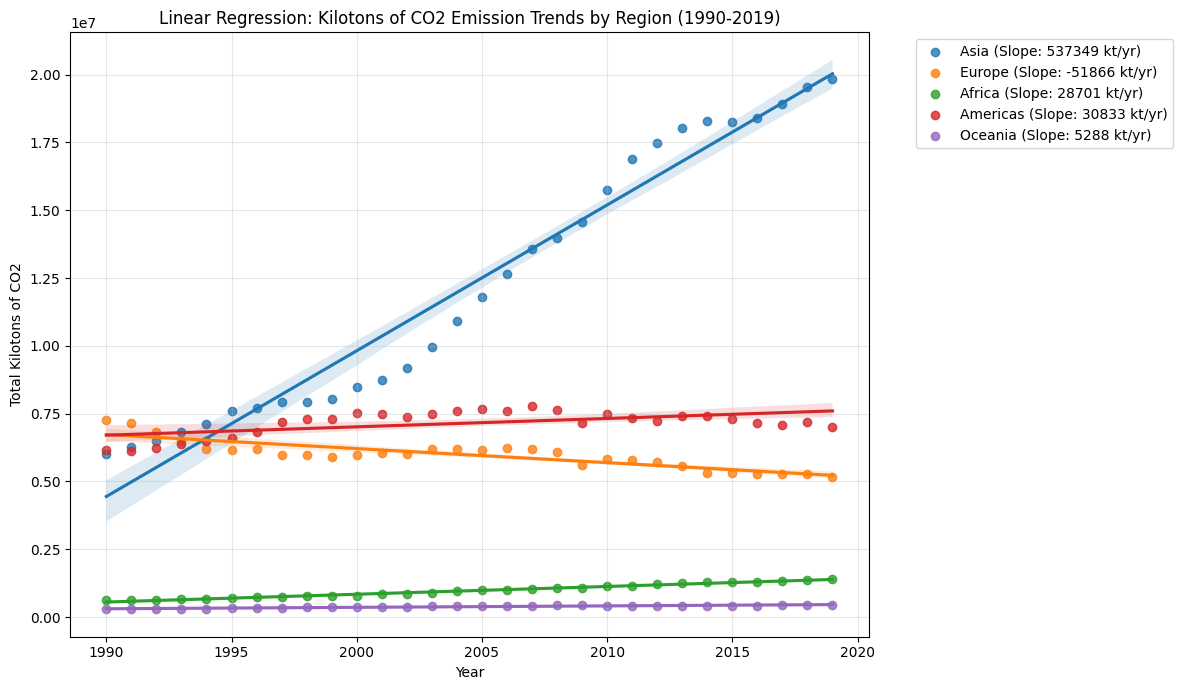

In [ ]:

# This loads the libraries used for the linear regression and plotting the regression lines on the scatter plot
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression


# Scikit. (2025). Linear Regression Example. Scikit-learn. https://scikit-learn.org/1.5/auto_examples/linear_model/plot_ols.html
# This loads the CO2 emissions dataset
dataset = pd.read_csv('Carbon_(CO2)_Emissions_by_Country.csv')

# This prepares the dataset for analysis by extracting the year from the date and getting the unique regions 
# These are the references for the date conversion and extracting the year(Unique value):
# Rhshadrach and Mroeschke. (2026). pandas.Series.dt.year. pandas. https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.year.html
# Star1327p . (2026). pandas.unique. pandas. https://pandas.pydata.org/docs/reference/api/pandas.unique.html
# Bhutani, K. (2025, June 24). Pandas.to_datetime()-Python. Geeksforgeeks.https://www.geeksforgeeks.org/pandas/python-pandas-to_datetime/
# Ranjan, S. (2025, July 11). Pandas Series dt.year | Extract Year Part from DateTime Series. Geeksforgeeks. https://www.geeksforgeeks.org/pandas/pandas-series-dt-year/
# Bhutani, K. (2018, September 17). Pandas Series.unique() - Python. Geeksforgeeks. https://www.geeksforgeeks.org/python/python-pandas-series-unique/
dataset['Date'] = pd.to_datetime(dataset['Date'], dayfirst = True)
dataset['Year'] = dataset['Date'].dt.year
regions = dataset['Region'].unique()

# This is for the size of the plot
# This is the reference for the figure size:
# Niharika. (2025, July 23). Change plot size in Matplotlib - Python. Geeksforgeeks. https://www.geeksforgeeks.org/python/change-plot-size-in-matplotlib-python/
plt.figure(figsize = (12, 7))

# This makes sure each regions data is filtered adn plotted seperately, and the slope of the regression line is calculated and displayed in the legend
for region in regions:
    region_filtered_data = dataset[dataset['Region'] == region]
    # This calculates the sum of the Kilotons of CO2 for each year for the each region
    region_trend = region_filtered_data.groupby('Year')['Kilotons of Co2'].sum().reset_index()
    
    # This allows the model to find a relationship between the year and the total Kilotons of CO2 for each region, which is used to plot the regression line
    # W3schools. (2023). Python Machine Learning - Linear Regression. https://www.w3schools.com/python/python_ml_linear_regression.asp
    model = LinearRegression().fit(region_trend[['Year']], region_trend['Kilotons of Co2'])
    
    # This plots everything on the scatter plot, and the label includes the region name and the slope of the regression line (which indicates the trend of CO2 emissions over time for that region)
    # Waskom, M. L. (2021). Seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://seaborn.pydata.org/generated/seaborn.regplot.html
    sns.regplot(x='Year', y='Kilotons of Co2', data = region_trend, 
                label=f'{region} (Slope: {model.coef_[0]:.0f} kt/yr)', ci = 95)

# This is for the title, axis labels, legend, grid and layout of the plot
plt.title('Linear Regression: Kilotons of CO2 Emission Trends by Region (1990-2019)')
plt.ylabel('Total Kilotons of CO2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Metric tons per capita

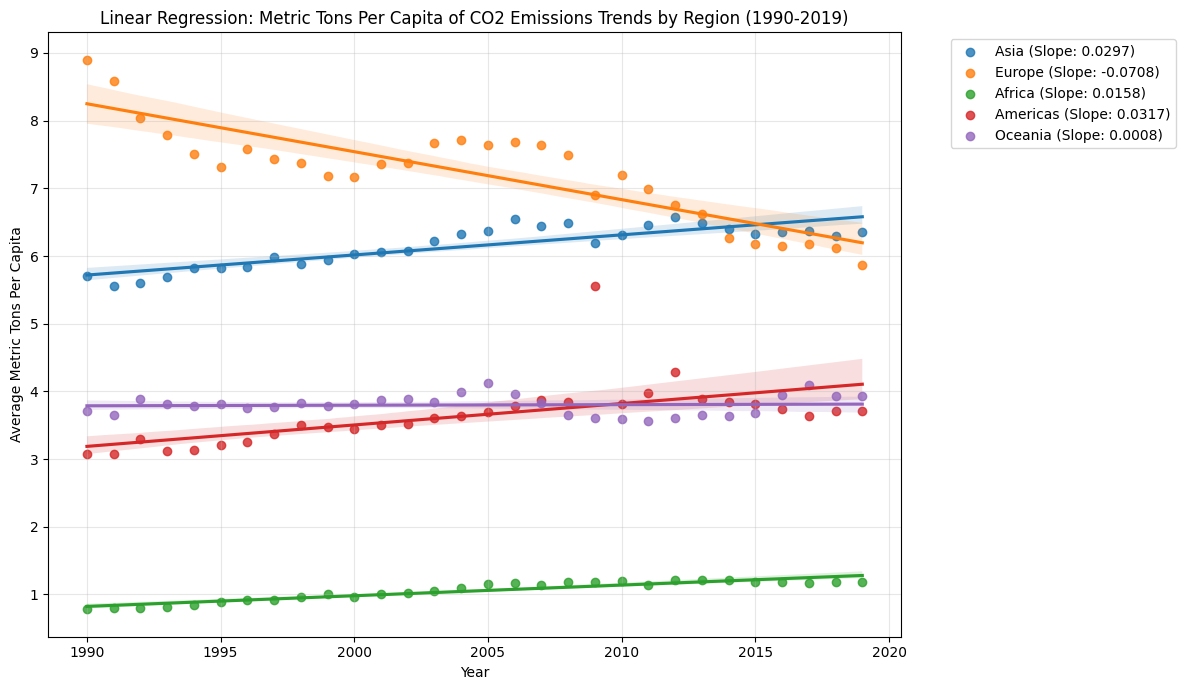

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Scikit. (2025). Linear Regression Example. Scikit-learn. https://scikit-learn.org/1.5/auto_examples/linear_model/plot_ols.html
# This loads the CO2 emissions dataset
dataset = pd.read_csv('Carbon_(CO2)_Emissions_by_Country.csv')

# This prepares the dataset for analysis by extracting the year from the date and getting the unique regions 
# These are the references for the date conversion and extracting the year(Unique value):
# Rhshadrach and Mroeschke. (2026). pandas.Series.dt.year. pandas. https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.year.html
# Star1327p . (2026). pandas.unique. pandas. https://pandas.pydata.org/docs/reference/api/pandas.unique.html
# Bhutani, K. (2025, June 24). Pandas.to_datetime()-Python. Geeksforgeeks.https://www.geeksforgeeks.org/pandas/python-pandas-to_datetime/
# Ranjan, S. (2025, July 11). Pandas Series dt.year | Extract Year Part from DateTime Series. Geeksforgeeks. https://www.geeksforgeeks.org/pandas/pandas-series-dt-year/
# Bhutani, K. (2018, September 17). Pandas Series.unique() - Python. Geeksforgeeks. https://www.geeksforgeeks.org/python/python-pandas-series-unique/
dataset['Date'] = pd.to_datetime(dataset['Date'], dayfirst=True)
dataset['Year'] = dataset['Date'].dt.year
regions = dataset['Region'].unique()

# This is for the size of the plot
# This is the reference for the figure size:
# Niharika. (2025, July 23). Change plot size in Matplotlib - Python. Geeksforgeeks. https://www.geeksforgeeks.org/python/change-plot-size-in-matplotlib-python/
plt.figure(figsize=(12, 7))

# This makes sure each regions data is filtered adn plotted seperately, and the slope of the regression line is calculated and displayed in the legend
for region in regions:
    region_df = dataset[dataset['Region'] == region]
   # This calculates the sum of the Kilotons of CO2 for each year for the each region
    region_capita = region_df.groupby('Year')['Metric Tons Per Capita'].mean().reset_index()
    
    # This allows the model to find a relationship between the year and the total Kilotons of CO2 for each region, which is used to plot the regression line
    # W3schools. (2023). Python Machine Learning - Linear Regression. https://www.w3schools.com/python/python_ml_linear_regression.asp
    model = LinearRegression().fit(region_capita[['Year']], region_capita['Metric Tons Per Capita'])
    
    # This plots everything on the scatter plot, and the label includes the region name and the slope of the regression line (which indicates the trend of CO2 emissions over time for that region)
    # Waskom, M. L. (2021). Seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://seaborn.pydata.org/generated/seaborn.regplot.html
    sns.regplot(x='Year', y='Metric Tons Per Capita', data=region_capita, 
                label=f'{region} (Slope: {model.coef_[0]:.4f})', ci=95)

# This is for the title, axis labels, legend, grid and layout of the plot
plt.title('Linear Regression: Metric Tons Per Capita of CO2 Emissions Trends by Region (1990-2019)')
plt.ylabel('Average Metric Tons Per Capita')
plt.xlabel('Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()